### CSE5026 Foundation and Frontiers of Cognitive Science
# Lab: F0 Analysis for Speech 

In this lab, you will first run through some basic time- and frequency-domain analysis on human speech signals. Then, wextract the **fundamental frequency (F0)** component from human speech signals, and compare their values from sentences of different prosodies (intonation types): a *statement* and a *question*. 


## Exercise 0. Record sample autio data

Use the `record.py` script to record your voice reading the same sentence twice, one in a declarative statement and the other in a question. 

For example, you can read "You know what I mean?" as a question, and "You know what I mean" as a statement. 

First, install the dependency [`pyaudio`](https://pypi.org/project/PyAudio/). Then run the following command:

```Python
$python record.py
```

After a countdown, it will start recording. Once you finished reading, press `Ctrl+C` to stop the recording. A .wav file will be saved in the current diretory. Remember to rename it accordingly. 

---


## Exercise 1. Visualize waveform

Plot the **time-domain waveform** of both recordings from Exercise 0: the statement and the question. 

If needed, install the third-party libraries: `pip install numpy scipy matplotlib`.

- Replace the two file paths below with your own recordings. 
- Call [`scipy.io.wavfile.read`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html) to obtain the sampling rate `sr` (samples per second) and the audio samples `audio`.
- Construct a time axis in seconds. Sample number `n` occurs at time `n / sr`, so use `np.arange(len(y)) / sr`. The recording duration is `len(y) / sr`.
- The `record.py` script in Exercise 0 saves **mono, 16-bit PCM** audio. Convert its integer samples to floating-point values by dividing by `32768.0`, giving amplitudes between -1 and +1.


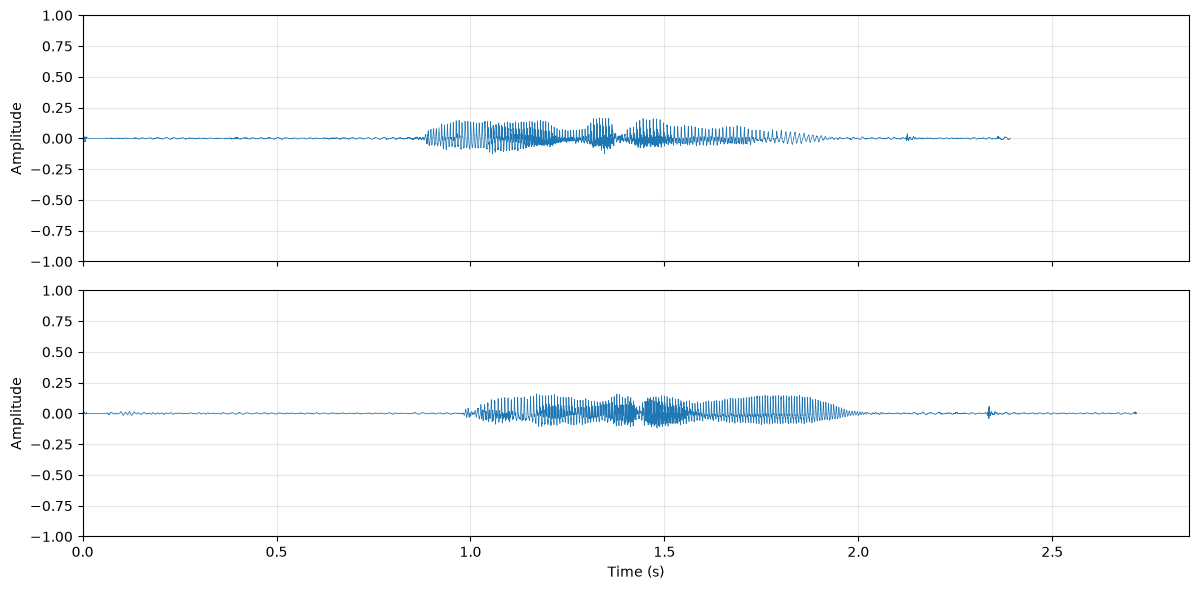

In [24]:
import numpy as np
from scipy.io import wavfile
import matplotlib.pyplot as plt

# Replace these with the paths to your recordings from Exercise 0.
statement_path = "u_no_what_I_mean.wav"
question_path = "u_no_what_I_mean?.wav"
recordings = [("Statement", statement_path), ("Question", question_path)]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)

for ax, (label, audio_path) in zip(axes, recordings):
    ### START YOUR CODE ###
    # TODO: Read the WAV file and obtain its sampling rate and samples.
    sr, audio = None, None

    # Exercise 0 produces mono, 16-bit PCM recordings.
    y = audio.astype(np.float64) / 32768.0

    # TODO: Convert sample numbers into time in seconds.
    times = None

    # TODO: Plot the waveform against time.
    pass
    ### END YOUR CODE ###

    # duration = len(y) / sr
    # print(f"{label}: {sr} samples/s, {len(y)} samples, {duration:.2f} s")
    # ax.set_title(f"{label}: time-domain waveform")
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-1, 1)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(left=0)
fig.tight_layout()
plt.show()


## Exercise 2. Frequency domain

Use `scipy.fft` to plot the **spectrum** of both recordings.

For preprocessing, the mean is subtracted from the signal to remove the DC offset and a Hann window is applied to reduce spectral leakage.

- Call [`scipy.fft.rfft`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.rfft.html) to compute the DFT of a real-valued signal. It returns the non-negative-frequency components.
- Call [`scipy.fft.rfftfreq`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.rfftfreq.html) with `d=1 / sr` to obtain their frequencies in Hz.
- Take `np.abs` of the complex FFT values and divide by the number of samples `N` to obtain a scaled magnitude spectrum. 

Then plot magnitude against frequency. For comparison, select a short voiced segment that elapses for less than 0.5 second, and plot the spectrum for that segment.

Run Exercise 1 first. Left panels show each full recording; right panels show a short voiced segment. 


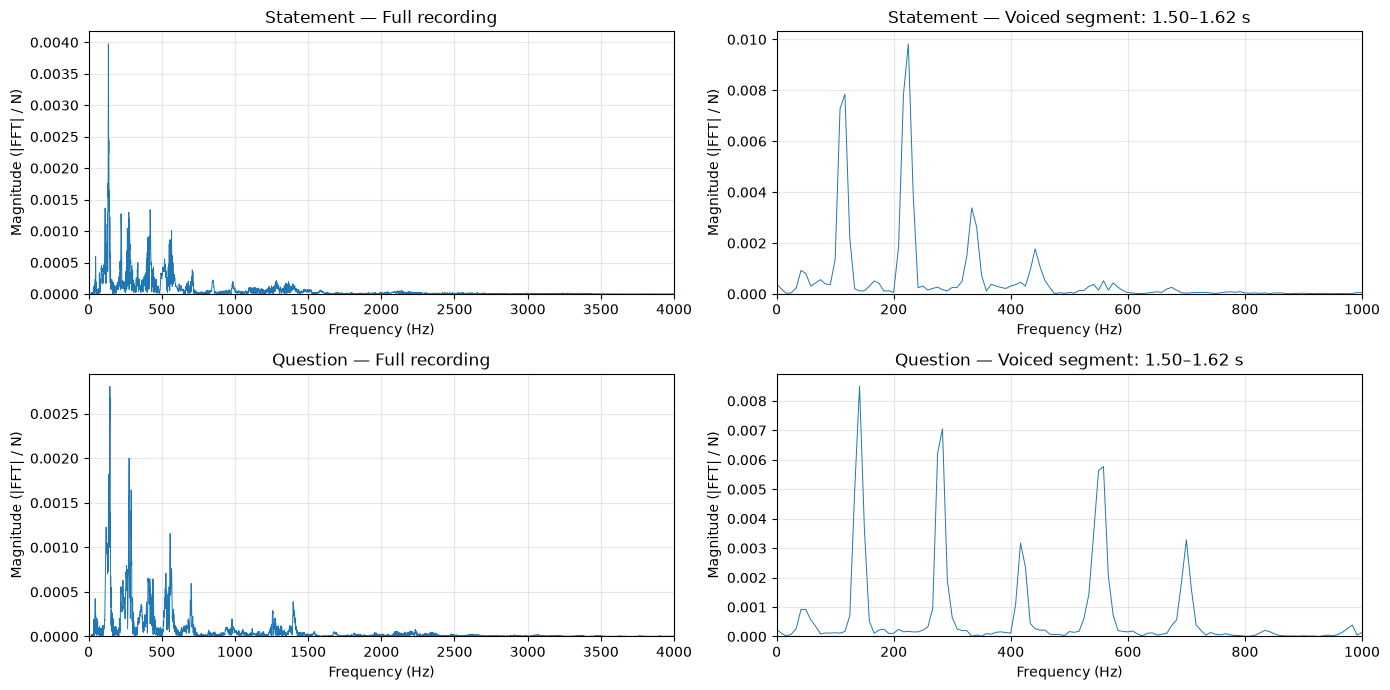

In [ ]:
def magnitude_spectrum(y, sr):
    N = len(y)
    windowed = (y - np.mean(y)) * np.hanning(N)

    ### START YOUR CODE ###
    # TODO: Compute the FFT of the real-valued signal.
    spectrum = None

    # TODO: Obtain the corresponding frequencies in Hz.
    frequencies = None

    # TODO: Convert the complex FFT values into scaled magnitudes.
    magnitude = None
    ### END YOUR CODE ###

    return frequencies, magnitude


# Example answers for the supplied recordings; update for your own audio.
# Each interval should contain a short, approximately steady voiced sound.
### START YOUR CODE ###
voiced_segments = {
    "Statement": (1.50, 1.62), 
    "Question": (1.50, 1.62)
}
### END YOUR CODE ###

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

for row, (label, audio_path) in enumerate(recordings):
    sr, audio = wavfile.read(audio_path)
    y = audio.astype(np.float64) / 32768.0

    start, end = voiced_segments[label]
    segment = y[int(start * sr):int(end * sr)]
    if not (0 <= start < end <= len(y) / sr) or len(segment) < 2:
        raise ValueError(f"Choose a valid voiced interval for {label}.")

    signals = [(y, "Full recording", 4000),
               (segment, f"Voiced segment: {start:.2f}–{end:.2f} s", 1000)]
    for col, (signal, title, max_frequency) in enumerate(signals):

        ### START YOUR CODE ###
        # TODO: Call the magnitude_spectrum() function.
        frequencies, magnitude = None, None
        ### END YOUR CODE ###

        ax = axes[row, col]
        ax.plot(frequencies, magnitude, linewidth=0.7)
        ax.set_xlim(0, min(max_frequency, sr / 2))
        ax.set_ylim(bottom=0)
        ax.set_title(f"{label} — {title}")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Magnitude (|FFT| / N)")
        ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


Next, use **Librosa** to plot a **spectrogram** of each full recording: time on the x-axis, frequency on the y-axis, and magnitude represented by color.

If needed, install it with `pip install librosa`.

- Call [`librosa.stft`](https://librosa.org/doc/0.11.0/generated/librosa.stft.html) to compute spectra over successive short windows. `n_fft` sets the window size in samples; `hop_length` sets the step between windows.
- Call `librosa.amplitude_to_db` on the STFT magnitudes. With `ref=np.max`, 0 dB represents the strongest component in each recording.
- Call [`librosa.display.specshow`](https://librosa.org/doc/0.11.0/generated/librosa.display.specshow.html) with `x_axis="time"` and `y_axis="linear"`. Pass the same `sr`, `n_fft`, and `hop_length` used for the STFT.

Locate the harmonic bands in voiced regions. How does their spacing change toward the end of the statement and question? 


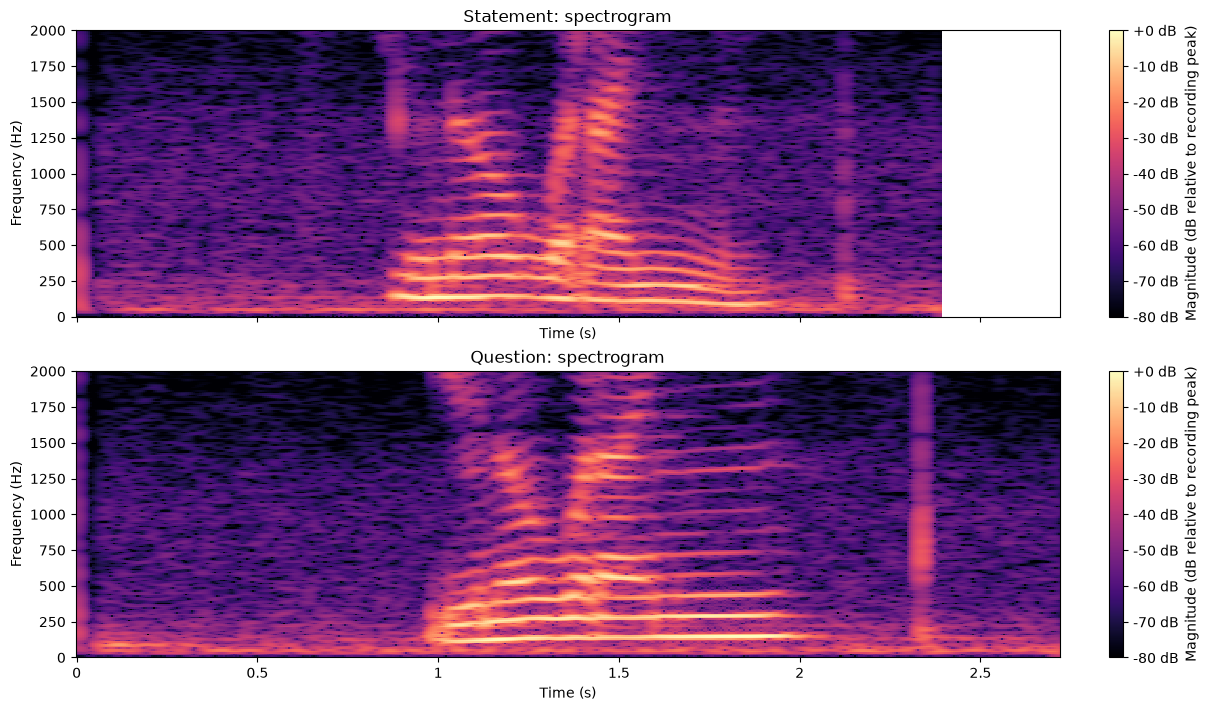

In [14]:
import librosa
import librosa.display

n_fft = 4096
hop_length = 256

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True,
                         constrained_layout=True)

for ax, (label, audio_path) in zip(axes, recordings):
    sr, audio = wavfile.read(audio_path)
    y = audio.astype(np.float64) / 32768.0

    # TODO: Compute the short-time Fourier transform.
    stft = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)

    # TODO: Convert magnitudes to dB relative to this recording's peak.
    magnitude_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

    # TODO: Display the spectrogram with time and frequency axes.
    image = librosa.display.specshow(
        magnitude_db, sr=sr, n_fft=n_fft, hop_length=hop_length,
        x_axis="time", y_axis="linear", ax=ax,
        cmap="magma", vmin=-80, vmax=0
    )
    ax.set_title(f"{label}: spectrogram")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, min(2000, sr / 2))  # Try 1000 Hz to inspect harmonic spacing.
    fig.colorbar(image, ax=ax, format="%+2.0f dB",
                 label="Magnitude (dB relative to recording peak)")

plt.show()


---

## Exercise 3. Extract F0 and plot

We are going to use some built-in functions in the `librosa` library to read the audio data and extract the F0 component. 



First, implement the following function, in which there are two TODO blocks to be filled. 

In the first block, you need to call `librosa.pyin` by passing the correct arguments. Probabilistic YIN ([pYIN](https://librosa.org/doc/0.11.0/generated/librosa.pyin.html)) is an algorithm for fundamental frequency (F0) estimation.  

In [ ]:
def extract_f0_amplitude(audio_path, method='pyin', hop_length=512, n_fft=4096, fmin=65, fmax=2093):
    """
    Extract F0 and its amplitude using 'pyin' method only.
    
    Args:
        audio_path (str): Path to audio file.
        method (str): 'pyin' only.
        hop_length (int): Samples between frames.
        n_fft (int): FFT window size (for amplitude extraction).
        fmin (float): Minimum frequency (Hz).
        fmax (float): Maximum frequency (Hz).
    
    Returns:
        f0 (np.ndarray): F0 values over time.
        sr (int): Sample rate.
        times (np.ndarray): Time stamps.
    """
    # Load audio
    y, sr = librosa.load(audio_path, sr=None)
    
    # Estimate F0 using selected method
    if method == 'pyin':
        # Use librosa's PYIN algorithm (more robust for complex signals)
        ### START YOUR CODE ###
        # TODO: Call librosa.pyin to obtain F0
        f0, _, _ = None, None, None
        ### END YOUR CODE ###
    else:
        raise ValueError("Method must be 'pyin' only.")
    
    # Time stamps
    times = librosa.times_like(f0, sr=sr, hop_length=hop_length)
    
    return f0, sr, times

Once the function is implemented, run the next cell to call it on your recorded audio data, and checkout the plot.

In [21]:
def f0_plot(audio_path):
    # Extract using 'pyin' method 
    f0, sr, times = extract_f0_amplitude(audio_path, method='pyin')
    
    # Plot results
    plt.figure(figsize=(14, 8))
    
    # Plot F0 
    plt.subplot(2, 1, 1)
    plt.plot(times, f0, label='PYIN F0', color='blue', alpha=0.7)
    plt.ylabel('Frequency (Hz)')
    plt.title('F0 Estimation Comparison')
    plt.legend()
    plt.tight_layout()
    
    # Save the plot to a file before showing
    plt.savefig(f'f0_{audio_path}.png', dpi=300, bbox_inches='tight')
    plt.show()

Plot two audios (statement and question) separately.

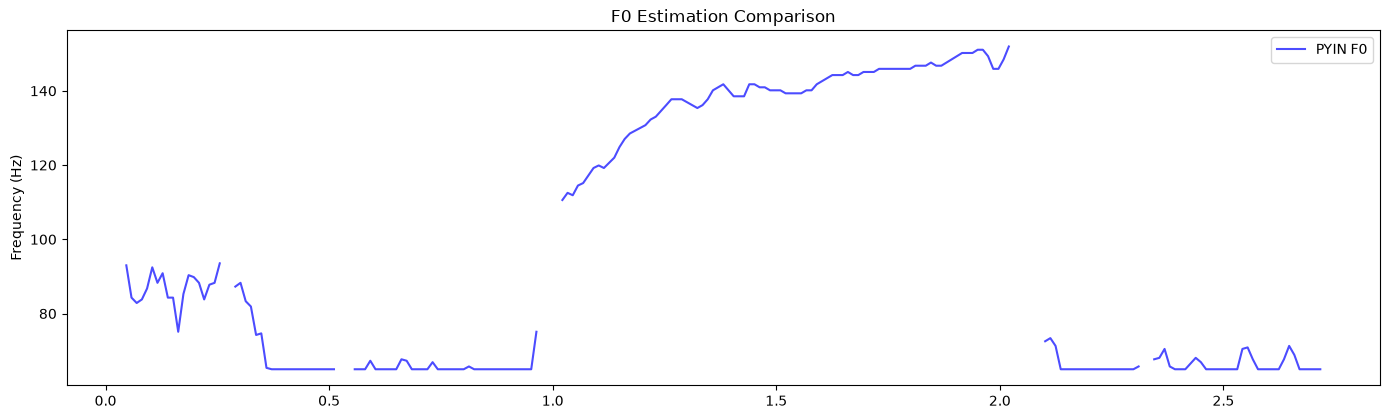

In [22]:
# Enter your audio path 
f0_plot(audio_path="u_no_what_I_mean?.wav")

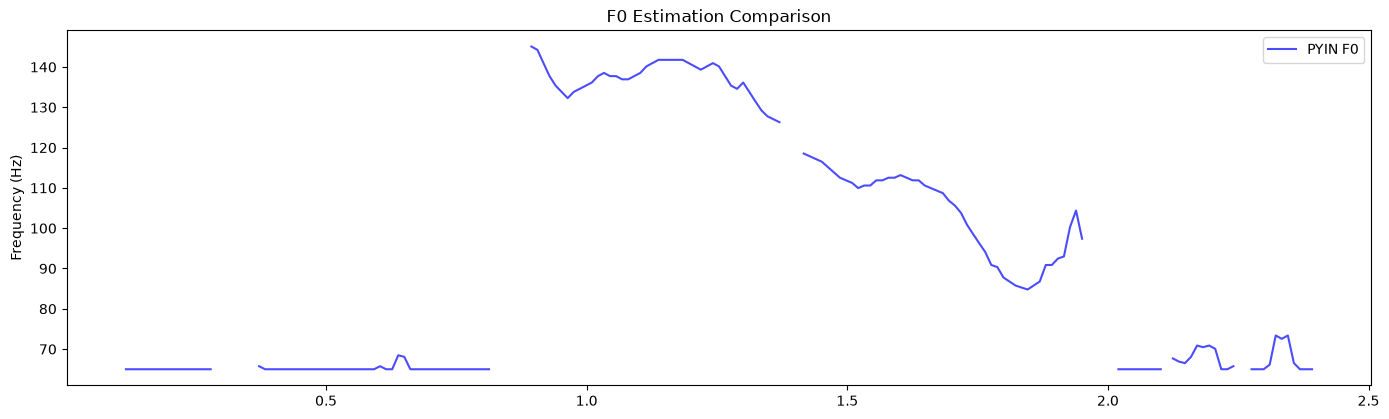

In [23]:
# Enter your audio path 
f0_plot(audio_path="u_no_what_I_mean.wav")

Can you see the difference in F0 between the statement and the question? 